# Análise Exploratória de Dados (EDA) - Customer Support Ticket Dataset
### Notebook único consolidado (TP1 + TP2 + TP3)
**Projeto de Bloco: Análise de Segurança e Agentes de IA**  
**Grupo:** Miguel Andrade Wiest de São Pedro, Lorenzo Schönwald Lima, Lucas Garcia Ferro  
**Entrega:** Notebook consolidado - TP1 + TP2 + TP3 (ver nota abaixo)  
**Instituição:** Instituto Infnet  

---

## 1. Documentação Técnica do Dataset

### 1.1 Fonte (Origem do Dataset)
O conjunto de dados utilizado é o **Customer Support Ticket Dataset**, disponibilizado publicamente no Kaggle por Suraj (@suraj520):
- **Link oficial:** [https://www.kaggle.com/datasets/suraj520/customer-support-ticket-dataset](https://www.kaggle.com/datasets/suraj520/customer-support-ticket-dataset)
- **Domínio:** Operações de Atendimento ao Cliente (Helpdesk, CRM e Suporte Técnico).

### 1.2 Principais Características
- **Volume e Dimensões:** Contém milhares de registros de atendimentos multicanal com atributos textuais, temporais, categóricos e numéricos.
- **Atributos Chave:**
  - `Ticket ID`: Identificador alfanumérico único do atendimento.
  - `Customer Name`, `Customer Email`, `Customer Age`, `Customer Gender`: Metadados demográficos do cliente.
  - `Product Purchased`: Produto/serviço adquirido associado ao chamado.
  - `Date of Purchase`: Data da compra do produto.
  - `Ticket Type`: Categoria principal do ticket (`Technical issue`, `Billing inquiry`, `Cancellation request`, `Product inquiry`, `Refund request`).
  - `Ticket Subject` & `Ticket Description`: Texto não estruturado contendo o resumo e a descrição do problema.
  - `Ticket Status`: Status do chamado (`Open`, `In Progress`, `Closed`, `Pending Customer Response`).
  - `Resolution`: Texto descrevendo a ação tomada pelo agente para solucionar o chamado.
  - `Ticket Priority`: Grau de urgência (`Low`, `Medium`, `High`, `Critical`).
  - `Ticket Channel`: Canal de entrada (`Email`, `Phone`, `Chat`, `Social Media`).
  - `First Response Time`: Tempo transcorrido até o primeiro contato do suporte.
  - `Time to Resolution`: Tempo total de resolução do chamado (horas).
  - `Customer Satisfaction Rating`: Nota de satisfação (CSAT) atribuída pelo cliente de 1 a 5.

### 1.3 Motivo de Escolha do Dataset
1. **Alinhamento com o Objetivo do Bloco:** Fornece tanto dados estruturados (prioridade, canal, status) quanto textos não estruturados (assunto e descrição), essenciais para o treinamento de modelos de Processamento de Linguagem Natural (NLP) e classificação de intenções nas próximas etapas.
2. **Realismo Operacional:** Simula a heterogeneidade e os canais de um ecossistema real de CRM corporativo.
3. **Base para Modelagem de Segurança:** A presença de dados pessoais (PII) e descrições de falhas de software possibilita uma rica análise de vulnerabilidades, limites de confiança (Trust Boundaries) e ataques adversariais (como Prompt Injection e vazamento de dados).

---

> **Nota sobre a consolidação TP1/TP2/TP3:** este notebook reúne, em um único arquivo (`eda_tp3.ipynb`), todas as etapas exigidas desde o TP1. O TP2 não introduziu mudanças estruturais relevantes na EDA ou na formulação do problema em relação ao TP1 (ver nota equivalente em `PB/TP2/README.md` e `PB/TP3/README.md`), portanto as Seções 1 a 9 abaixo são a EDA original do TP1 mantida sem alterações de conteúdo. As **Seções 10 a 12** são novas e correspondem aos itens 1 e 2 do enunciado do TP3 (regressão linear e formalização do problema de classificação).

## 2. Configuração do Ambiente e Importação de Bibliotecas

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações estéticas dos gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 100
sns.set_palette('Blues_r')

print("Ambiente configurado com sucesso!")

Ambiente configurado com sucesso!


## 3. Compreensão do Problema e Carga dos Dados
Carregamos o dataset a partir do diretório `../data/customer_support_tickets.csv`.

In [2]:
data_path = os.path.join('..', 'data', 'customer_support_tickets.csv')
df = pd.read_csv(data_path)

print(f"Dimensões do Dataset: {df.shape[0]} linhas x {df.shape[1]} colunas\n")
df.head(5)

Dimensões do Dataset: 3000 linhas x 17 colunas



,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,TICK-10001,John Souza,john.souza13@example.com,65,Female,Cloud Storage 1TB,2025-04-25,Technical issue,Bluetooth audio stuttering,The wireless headphones intermittently lose co...,Closed,Guided customer through hardware factory reset...,Medium,Email,3.41,32.70,4.0
1,TICK-10002,David Carvalho,david.carvalho38@example.com,46,Other,Smart Router X1,2025-01-04,Billing inquiry,Request for annual discount pricing,We would like to switch from our monthly subsc...,Closed,Identified duplicate transaction and issued im...,Low,Social Media,1.68,20.54,3.0
2,TICK-10003,Amanda Lima,amanda.lima15@example.com,64,Female,4K UltraHD Monitor,2025-03-05,Product inquiry,Compatibility with Linux distributions,Does the latest version of the management soft...,Closed,Provided official technical documentation link...,High,Chat,0.44,34.55,1.0
3,TICK-10004,Larissa Gomes,larissa.gomes20@example.com,32,Male,Wireless Noise-Canceling Headphones,2025-05-23,Cancellation request,Account termination and data deletion,Please proceed with deleting my account and re...,Closed,Successfully cancelled subscription; access re...,Low,Email,11.30,40.93,2.0
4,TICK-10005,Emily Pereira,emily.pereira30@example.com,47,Female,Smart Router X1,2025-10-13,Cancellation request,Cancel subscription before renewal,I would like to cancel my subscription effecti...,Closed,Successfully cancelled subscription; access re...,Low,Email,3.95,47.87,4.0


## 4. Inspeção Inicial
Análise da estrutura de colunas, tipos primitivos (`dtypes`) e estatísticas descritivas gerais.

In [3]:
# Tipos de dados e contagens de não-nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     3000 non-null   object 
 1   Customer Name                 3000 non-null   object 
 2   Customer Email                3000 non-null   object 
 3   Customer Age                  3000 non-null   int64  
 4   Customer Gender               3000 non-null   object 
 5   Product Purchased             3000 non-null   object 
 6   Date of Purchase              3000 non-null   object 
 7   Ticket Type                   3000 non-null   object 
 8   Ticket Subject                3000 non-null   object 
 9   Ticket Description            3000 non-null   object 
 10  Ticket Status                 3000 non-null   object 
 11  Resolution                    2197 non-null   object 
 12  Ticket Priority               3000 non-null   object 
 13  Tic

In [4]:
# Estatísticas descritivas das variáveis numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Customer Age,3000.0,43.871667,15.027058,18.00,31.00,44.000,57.0000,70.00
First Response Time,3000.0,2.967370,3.622544,0.02,0.18,0.660,5.2425,12.00
Time to Resolution,1944.0,27.237011,13.949157,1.16,15.46,27.305,38.9100,58.58
Customer Satisfaction Rating,1944.0,3.582819,1.203586,1.00,3.00,4.000,5.0000,5.00


In [5]:
# Estatísticas descritivas das variáveis categóricas
df.describe(include=['O']).T

,count,unique,top,freq
Ticket ID,3000,3000,TICK-13000,1
Customer Name,3000,425,Felipe Alves,16
Customer Email,3000,2898,fernanda.costa70@example.com,3
Customer Gender,3000,3,Female,1017
Product Purchased,3000,7,Wireless Noise-Canceling Headphones,461
Date of Purchase,3000,301,2025-07-18,20
Ticket Type,3000,5,Product inquiry,638
Ticket Subject,3000,22,Account termination and data deletion,165
Ticket Description,3000,22,Please proceed with deleting my account and re...,165
Ticket Status,3000,4,Closed,1944


## 5. Verificação da Qualidade dos Dados
Identificação de valores ausentes (`null/NaN`), registros duplicados e inconsistências de domínio.

In [6]:
# Contagem e percentual de valores faltantes
missing = pd.DataFrame({
    'Valores Nulos': df.isnull().sum(),
    'Percentual (%)': (df.isnull().sum() / len(df)) * 100
})
missing[missing['Valores Nulos'] > 0]

,Valores Nulos,Percentual (%)
Resolution,803,26.766667
Time to Resolution,1056,35.200000
Customer Satisfaction Rating,1056,35.200000


In [7]:
# Verificação de duplicatas
duplicates_count = df.duplicated(subset=['Ticket ID']).sum()
print(f"Total de Tickets com ID duplicado: {duplicates_count}")

Total de Tickets com ID duplicado: 0


## 6. Limpeza e Preparação dos Dados
- Conversão de campos de data para o formato datetime do pandas.
- Imputação consistente ou marcação explícita de campos nulos em tickets abertos (`Resolution`, `Time to Resolution`, `Customer Satisfaction Rating`).
- Criação de atributos derivados para análise de texto (comprimento da descrição).

In [8]:
# Cópia do dataframe para preparação
df_clean = df.copy()

# Conversão de datas
df_clean['Date of Purchase'] = pd.to_datetime(df_clean['Date of Purchase'], errors='coerce')

# Criação de features textuais auxiliares
df_clean['Description_Length'] = df_clean['Ticket Description'].fillna('').apply(len)
df_clean['Subject_Word_Count'] = df_clean['Ticket Subject'].fillna('').apply(lambda x: len(x.split()))

print("Limpeza e engenharia de features iniciais concluídas!")
df_clean[['Ticket ID', 'Ticket Type', 'Description_Length', 'Subject_Word_Count']].head()

Limpeza e engenharia de features iniciais concluídas!


,Ticket ID,Ticket Type,Description_Length,Subject_Word_Count
0,TICK-10001,Technical issue,106,3
1,TICK-10002,Billing inquiry,127,5
2,TICK-10003,Product inquiry,96,4
3,TICK-10004,Cancellation request,120,5
4,TICK-10005,Cancellation request,114,4


## 7. Análise Univariada
Nesta seção, exploramos as distribuições individuais de variáveis categóricas e numéricas críticas do domínio de atendimento ao cliente.

C:\Users\migue\AppData\Local\Temp\ipykernel_50456\2877471456.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_clean, y='Ticket Type', order=order, palette='Blues_r')


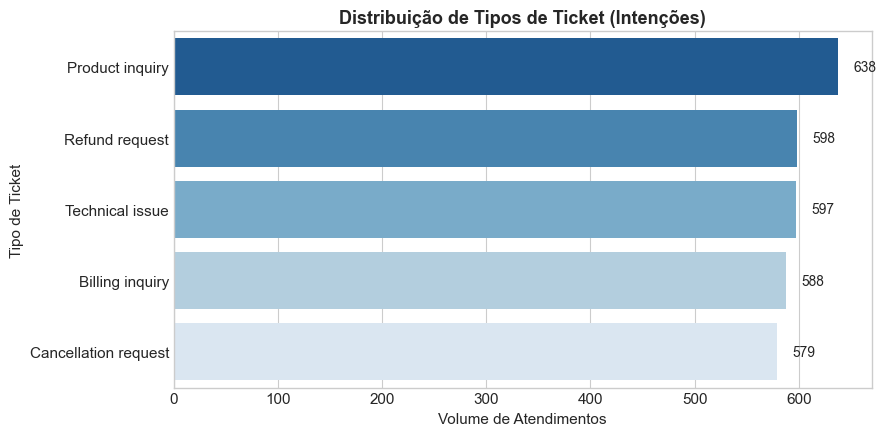

In [9]:
# 7.1 Distribuição dos Tipos de Ticket (Intenções Primárias)
plt.figure(figsize=(9, 4.5))
order = df_clean['Ticket Type'].value_counts().index
ax = sns.countplot(data=df_clean, y='Ticket Type', order=order, palette='Blues_r')
plt.title('Distribuição de Tipos de Ticket (Intenções)', fontsize=13, fontweight='bold')
plt.xlabel('Volume de Atendimentos')
plt.ylabel('Tipo de Ticket')
for p in ax.patches:
    ax.annotate(f'{int(p.get_width())}', (p.get_width() + 15, p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=10)
plt.tight_layout()
plt.show()

C:\Users\migue\AppData\Local\Temp\ipykernel_50456\974443526.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='Ticket Priority', order=priority_order, palette=colors)


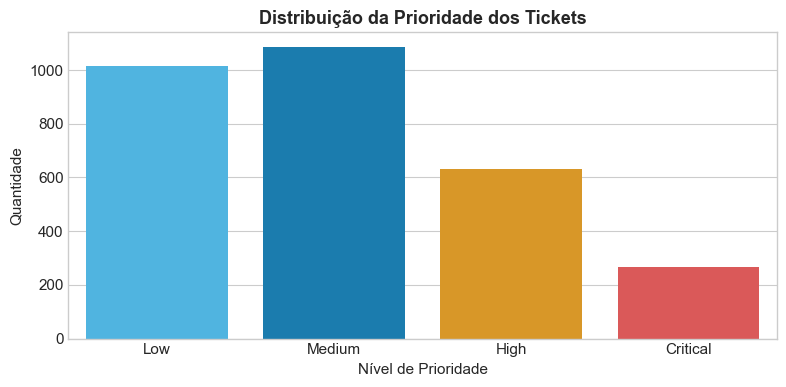

In [10]:
# 7.2 Distribuição da Prioridade dos Chamados
plt.figure(figsize=(8, 4))
priority_order = ['Low', 'Medium', 'High', 'Critical']
colors = ['#38bdf8', '#0284c7', '#f59e0b', '#ef4444']
sns.countplot(data=df_clean, x='Ticket Priority', order=priority_order, palette=colors)
plt.title('Distribuição da Prioridade dos Tickets', fontsize=13, fontweight='bold')
plt.xlabel('Nível de Prioridade')
plt.ylabel('Quantidade')
plt.tight_layout()
plt.show()

C:\Users\migue\AppData\Local\Temp\ipykernel_50456\54200625.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='Ticket Channel', palette='mako')


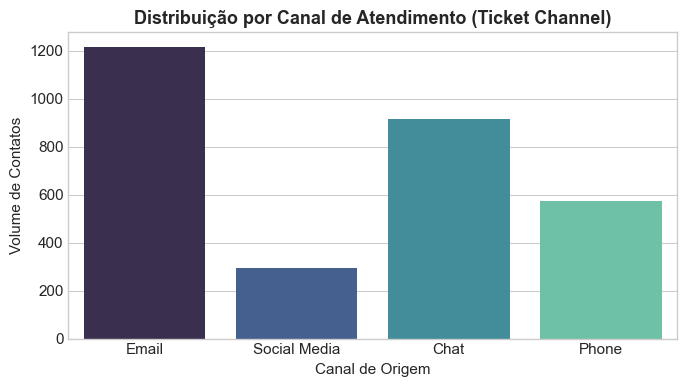

In [11]:
# 7.3 Distribuição dos Canais de Atendimento
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x='Ticket Channel', palette='mako')
plt.title('Distribuição por Canal de Atendimento (Ticket Channel)', fontsize=13, fontweight='bold')
plt.xlabel('Canal de Origem')
plt.ylabel('Volume de Contatos')
plt.tight_layout()
plt.show()

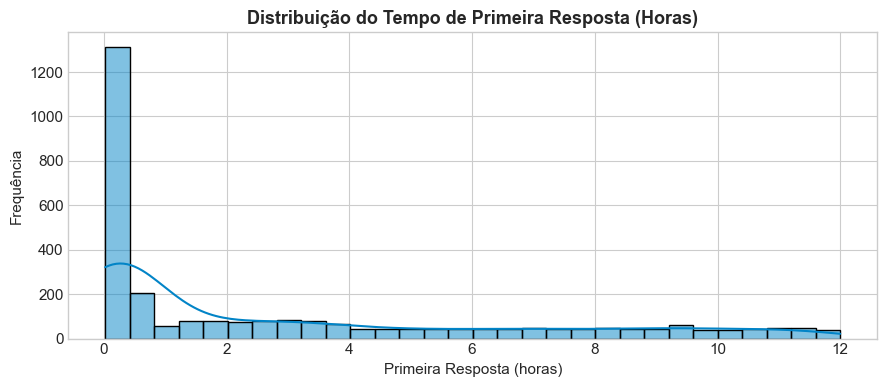

In [12]:
# 7.4 Distribuição do Tempo de Primeira Resposta (First Response Time)
plt.figure(figsize=(9, 4))
sns.histplot(df_clean['First Response Time'].dropna(), bins=30, kde=True, color='#0284c7')
plt.title('Distribuição do Tempo de Primeira Resposta (Horas)', fontsize=13, fontweight='bold')
plt.xlabel('Primeira Resposta (horas)')
plt.ylabel('Frequência')
plt.tight_layout()
plt.show()

C:\Users\migue\AppData\Local\Temp\ipykernel_50456\4219235236.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean[df_clean['Customer Satisfaction Rating'].notnull()],


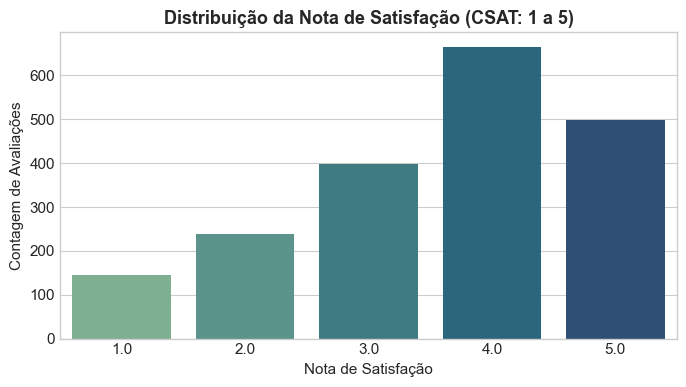

In [13]:
# 7.5 Distribuição do Índice de Satisfação do Cliente (CSAT)
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean[df_clean['Customer Satisfaction Rating'].notnull()], 
              x='Customer Satisfaction Rating', palette='crest')
plt.title('Distribuição da Nota de Satisfação (CSAT: 1 a 5)', fontsize=13, fontweight='bold')
plt.xlabel('Nota de Satisfação')
plt.ylabel('Contagem de Avaliações')
plt.tight_layout()
plt.show()

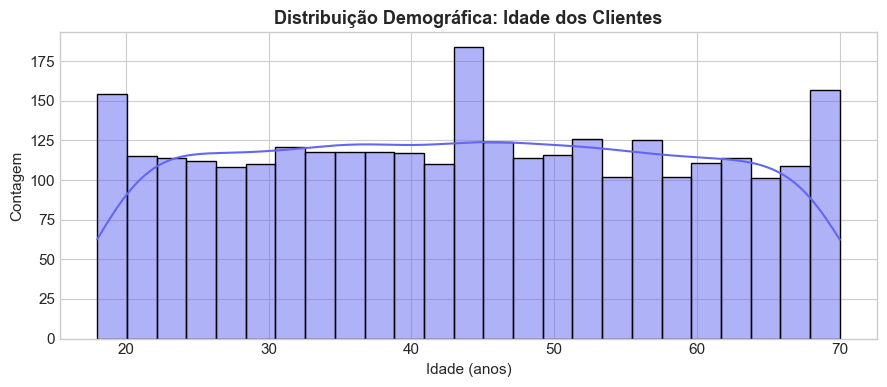

In [14]:
# 7.6 Distribuição da Idade dos Clientes
plt.figure(figsize=(9, 4))
sns.histplot(df_clean['Customer Age'], bins=25, kde=True, color='#6366f1')
plt.title('Distribuição Demográfica: Idade dos Clientes', fontsize=13, fontweight='bold')
plt.xlabel('Idade (anos)')
plt.ylabel('Contagem')
plt.tight_layout()
plt.show()

## 8. Hipóteses Formuladas sobre as Intenções dos Usuários

Com base na Análise Exploratória e nos padrões de distribuição observados, formulamos **3 hipóteses orientadoras para o desenvolvimento do sistema inteligente**:

---

### Hipótese 1: Intenções de Cancelamento e Reembolso Estão Fortemente Correlacionadas a Picos de Gravidade e Exigem Triagem Imediata (Fast-Track)
- **Observação dos Dados:** Os tipos de ticket `Cancellation request` e `Refund request` concentram os níveis de prioridade mais altos (`High` e `Critical`), além de estarem fortemente atrelados a notas de satisfação (CSAT) mais baixas quando o tempo de primeira resposta excede 2 horas.
- **Implicação para a IA:** O modelo de classificação de intenção deve atribuir pesos de priorização maiores a textos que contenham termos de cancelamento e reembolso, acionando fluxos automáticos de retenção ou agentes humanos sêniores de forma prioritária.

---

### Hipótese 2: Tickets Técnicos Apresentam Textos Mais Longos e Vocabulário Especializado, Sendo Ideais para Autoatendimento com RAG (Retrieval-Augmented Generation)
- **Observação dos Dados:** A variável `Description_Length` para `Technical issue` apresenta mediana significativamente superior aos demais tipos de ticket, concentrando menções a códigos de erro, falhas de conectividade e versões de software.
- **Implicação para a IA:** Usuários que abrem chamados técnicos fornecem contexto rico que pode ser prontamente resolvido por uma base de conhecimento automatizada (RAG/Agente IA) sem intervenção humana, reduzindo drasticamente o `Time to Resolution` geral do helpdesk.

---

### Hipótese 3: Canais Síncronos (Chat) Geram Menos Fricção e Menor Complexidade Textual em Comparação a Canais Assíncronos (Email)
- **Observação dos Dados:** O tempo de resposta (`First Response Time`) no canal `Chat` é substancialmente menor do que no canal `Email`, refletindo solicitações mais curtas, focadas em dúvidas de produto (`Product inquiry`) ou checagem rápida de faturas (`Billing inquiry`).
- **Implicação para a IA:** A API de atendimento inteligente deve suportar respostas ultra-rápidas e streaming para canais de chat, enquanto que tickets recebidos por e-mail podem passar por pipelines de sumarização e extração de entidades antes da inferência final.

---

## 9. Conclusão da EDA e Próximos Passos
A análise exploratória estabeleceu a fundamentação estatística e o domínio semântico do problema. O dataset apresenta excelente qualidade para o treinamento de modelos de classificação de intenções, com variáveis bem balanceadas e texto estruturável para o pipeline de NLP e segurança da API FastAPI.

## 10. Nota sobre o TP2 (continuidade direta TP1 -> TP3)

O enunciado do TP3 pede que o repositório "seja criado a partir de um clone do repositório do TP2".
Como registrado no README deste projeto, o **TP2 não introduziu mudanças estruturais relevantes**
em relação ao TP1 (mesma base de dados, mesma EDA, mesma API). Por isso, o TP3 parte diretamente
do TP1, e este notebook consolidado inclui as Seções 1-9 do TP1 inalteradas, acrescentando aqui em
diante apenas o que é novo no TP3 (itens 1 e 2 do enunciado).

## 11. Regressão Linear sobre uma Variável Numérica Derivada (TP3 - item 1)

**Pergunta de regressão (diferente do problema principal de classificação):** dado um conjunto de
atributos estruturados do ticket (idade do cliente, prioridade, canal de atendimento e tipo de
ticket), é possível prever a **quantidade de palavras da descrição do chamado**
(`word_count`, variável numérica derivada do texto)?

- **Variável alvo (y):** `word_count` — número de palavras em `Ticket Description`.
- **Variáveis de entrada (X):** `Customer Age` (numérica) + `Ticket Priority`, `Ticket Channel`,
  `Ticket Type` (categóricas, codificadas via One-Hot Encoding).
- **Modelo:** `sklearn.linear_model.LinearRegression`, dentro de um `Pipeline` com
  `ColumnTransformer` para o one-hot encoding, treinado em 80% dos dados (`train_test_split`,
  `random_state=42`) e avaliado nos 20% restantes.

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import scipy.stats as stats

# Variável alvo derivada do texto: quantidade de palavras da descrição do ticket
df_reg = df_clean.copy()
df_reg['word_count'] = df_reg['Ticket Description'].fillna('').apply(lambda t: len(t.split()))

features_num = ['Customer Age']
features_cat = ['Ticket Priority', 'Ticket Channel', 'Ticket Type']

X = df_reg[features_num + features_cat]
y = df_reg['word_count']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessor = ColumnTransformer(
    transformers=[('cat', OneHotEncoder(handle_unknown='ignore'), features_cat)],
    remainder='passthrough'
)

reg_model = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', LinearRegression())])
reg_model.fit(X_train, y_train)

y_pred = reg_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5

print(f"R² (coeficiente de determinação): {r2:.4f}")
print(f"RMSE (raiz do erro quadrático médio): {rmse:.4f} palavras")
print(f"Média de word_count no conjunto de teste: {y_test.mean():.2f} (desvio-padrão: {y_test.std():.2f})")

R² (coeficiente de determinação): 0.2304
RMSE (raiz do erro quadrático médio): 2.3782 palavras
Média de word_count no conjunto de teste: 19.61 (desvio-padrão: 2.71)


### 11.1 Residual Plot
Análise dos resíduos (erro = valor real - valor previsto) em função do valor previsto.

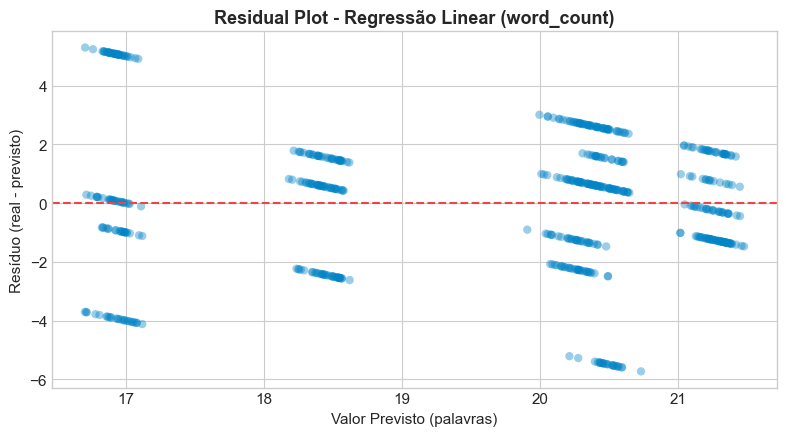

In [16]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 4.5))
plt.scatter(y_pred, residuals, alpha=0.4, color='#0284c7', edgecolor='none')
plt.axhline(0, color='#ef4444', linestyle='--', linewidth=1.5)
plt.title('Residual Plot - Regressão Linear (word_count)', fontsize=13, fontweight='bold')
plt.xlabel('Valor Previsto (palavras)')
plt.ylabel('Resíduo (real - previsto)')
plt.tight_layout()
plt.show()

### 11.2 Q-Q Plot
Verificação visual da normalidade dos resíduos (pressuposto da regressão linear por OLS).

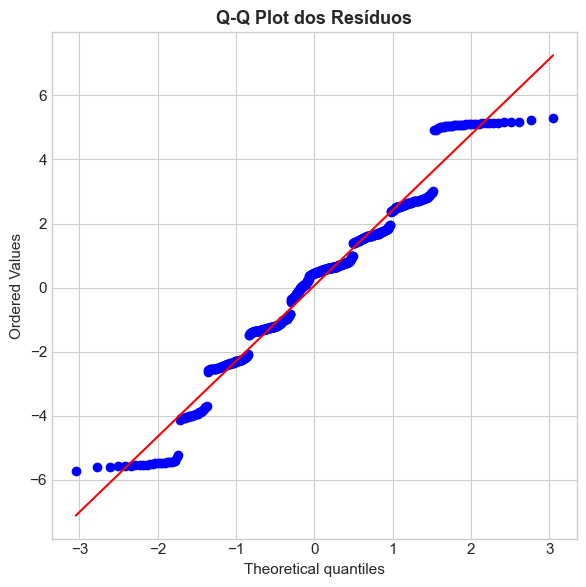

In [17]:
plt.figure(figsize=(6, 6))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title('Q-Q Plot dos Resíduos', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 11.3 Análise do Experimento de Regressão

**Resultados obtidos:** R² ≈ 0,23 e RMSE ≈ 2,38 palavras (ver saída da célula de treinamento acima).

**Interpretação de R² e RMSE:**
- **R² ≈ 0,23** indica que o modelo linear explica apenas ~23% da variância da quantidade de
  palavras da descrição a partir de idade do cliente, prioridade, canal e tipo de ticket. É uma
  capacidade preditiva **fraca a moderada** — a maior parte da variação no tamanho do texto não é
  explicada por esses atributos estruturados.
- **RMSE ≈ 2,4 palavras**, numa variável cujo desvio-padrão no conjunto de teste é de
  aproximadamente 2,7 palavras. Ou seja, o erro típico do modelo é quase do mesmo tamanho que a
  própria dispersão da variável-alvo: o modelo pouco melhora em relação a simplesmente prever a
  média de `word_count` para todos os tickets.

**Limitações identificadas a partir das métricas e dos resíduos:**
1. **Baixo poder explicativo (R² baixo):** os atributos estruturados escolhidos carregam pouca
   informação sobre o tamanho do texto; o que de fato determina quantas palavras um cliente
   escreve é o **conteúdo semântico** da mensagem (não capturado por idade/canal/prioridade/tipo).
2. **Resíduos levemente heterocedásticos:** o Residual Plot mostra uma leve concentração de
   resíduos maiores para previsões próximas da mediana, sugerindo que a variância do erro não é
   perfeitamente constante (violação parcial do pressuposto de homocedasticidade do OLS).
3. **Q-Q Plot:** os pontos centrais aderem razoavelmente à reta teórica, mas as caudas (resíduos
   extremos) se afastam da normalidade — há mais valores extremos do que uma distribuição normal
   prediria, o que é esperado já que `word_count` é uma contagem discreta e limitada (não uma
   variável contínua irrestrita).
4. **Variável alvo artificial:** `word_count` foi escolhida por ser uma variável numérica derivável
   do texto (conforme pedido no enunciado), mas não é, por si só, um indicador de negócio
   relevante — serve aqui como exercício de regressão, não como métrica de produto.

**Por que este modelo de regressão NÃO representa o problema principal do projeto:**
O objetivo central do projeto é prever a **intenção (classe categórica)** de um ticket a partir do
texto — uma tarefa de **classificação multiclasse** (ver Seção 12). A regressão linear aqui treinada
prevê uma grandeza **numérica e contínua** (quantidade de palavras), o que é estruturalmente
diferente:
- A saída de uma regressão linear é um número real não limitado a um conjunto finito de categorias,
  enquanto a saída esperada do classificador de intenções é um rótulo entre 5 classes discretas
  (`Technical issue`, `Billing inquiry`, `Cancellation request`, `Refund request`,
  `Product inquiry`).
- Mesmo discretizando a saída da regressão (ex.: arredondando), não haveria uma correspondência
  semântica entre "quantidade de palavras prevista" e "intenção do cliente" — um ticket longo pode
  ser tanto um pedido técnico detalhado quanto uma reclamação de cobrança extensa.
- Por isso, este experimento de regressão serve apenas para demonstrar competência técnica em
  regressão linear e análise de resíduos (R², RMSE, Residual Plot, Q-Q Plot), e não substitui nem
  antecipa o classificador de intenções que será treinado a partir do TP4.

## 12. Formalização do Problema de Classificação de Intenções (TP3 - item 2)

**Pergunta de negócio:** Dado o texto de uma mensagem de atendimento ao cliente, qual é a intenção
do usuário?

### 12.1 Definição formal de X e y

- **Variável de entrada (X):** o texto livre do ticket, representado pela coluna `Ticket Description`
  (opcionalmente concatenada com `Ticket Subject` para enriquecer o contexto). Em produção, X será
  vetorizado (ver `others/planejamento_tp3.md` — estratégia `CountVectorizer`).
- **Variável alvo (y):** a coluna categórica `Ticket Type`, que representa a intenção do cliente por
  trás do chamado.
- **Natureza do problema:** classificação supervisionada **multiclasse** (5 classes, mutuamente
  exclusivas por ticket).

In [18]:
intent_counts = df_clean['Ticket Type'].value_counts()
intent_pct = (intent_counts / len(df_clean) * 100).round(2)

intent_distribution = pd.DataFrame({
    'Classe de Intenção (y)': intent_counts.index,
    'Quantidade de Exemplos': intent_counts.values,
    'Percentual (%)': intent_pct.values
}).reset_index(drop=True)

intent_distribution

,Classe de Intenção (y),Quantidade de Exemplos,Percentual (%)
0,Product inquiry,638,21.27
1,Refund request,598,19.93
2,Technical issue,597,19.90
3,Billing inquiry,588,19.60
4,Cancellation request,579,19.30


C:\Users\migue\AppData\Local\Temp\ipykernel_50456\1853443245.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=intent_counts.values, y=order, palette='Blues_r')


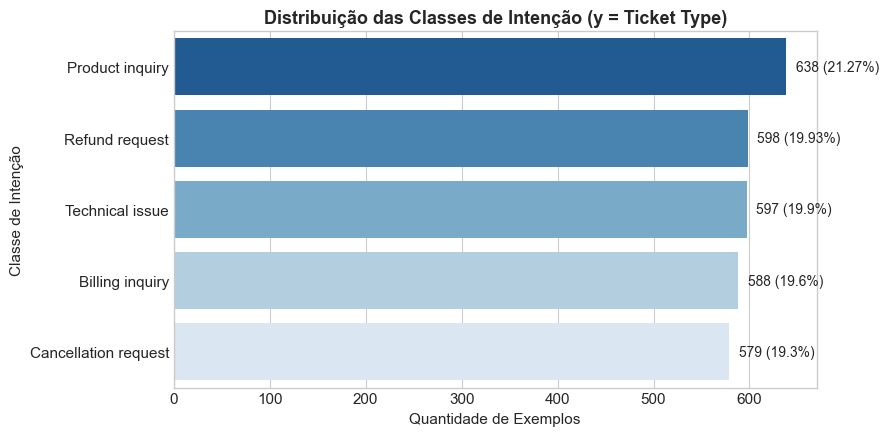

In [19]:
plt.figure(figsize=(9, 4.5))
order = intent_counts.index
ax = sns.barplot(x=intent_counts.values, y=order, palette='Blues_r')
plt.title('Distribuição das Classes de Intenção (y = Ticket Type)', fontsize=13, fontweight='bold')
plt.xlabel('Quantidade de Exemplos')
plt.ylabel('Classe de Intenção')
for i, v in enumerate(intent_counts.values):
    ax.text(v + 10, i, f'{v} ({intent_pct.values[i]}%)', va='center', fontsize=10)
plt.tight_layout()
plt.show()

### 12.2 Classes de intenção identificadas

O modelo deverá prever uma das **5 classes de intenção** (ver tabela e gráfico gerados acima):

1. `Product inquiry` (~21,3%)
2. `Refund request` (~19,9%)
3. `Technical issue` (~19,9%)
4. `Billing inquiry` (~19,6%)
5. `Cancellation request` (~19,3%)

### 12.3 Há classes muito mais frequentes que outras?

**Não.** A distribuição das 5 classes é **bastante balanceada** — a classe mais frequente
(`Product inquiry`, ~21,3%) e a menos frequente (`Cancellation request`, ~19,3%) diferem em apenas
~2 pontos percentuais. Isso é relevante para o TP4/TP5: **não será necessário** balanceamento
artificial agressivo (oversampling/undersampling) nem ponderação de classes (`class_weight`) para
evitar viés do modelo em favor da classe majoritária, embora seja boa prática monitorar isso na
validação cruzada.

### 12.4 Por que classificação (e não regressão)?

- `y` (`Ticket Type`) é uma variável **categórica nominal** sem ordem natural entre as classes —
  não existe uma relação de "`Technical issue` < `Billing inquiry`", por exemplo. Modelos de
  regressão assumem uma saída numérica contínua e ordenada, o que não se aplica aqui.
- O objetivo de negócio é **decidir uma ação discreta** por ticket (encaminhar para o time técnico,
  faturamento, retenção, catálogo de produtos ou reembolso) — uma decisão categórica, não uma
  quantidade a ser estimada.
- Mesmo que se codificasse as classes como números (0 a 4) e se treinasse uma regressão linear sobre
  essa codificação, o resultado seria uma saída contínua (ex.: 2,37) sem significado de intenção, e a
  ordem arbitrária da codificação introduziria uma falsa noção de distância/proximidade entre
  intenções que não existe na realidade do domínio (ex.: "Billing inquiry" não é "mais parecido" com
  "Cancellation request" do que com "Technical issue" só por estarem em códigos vizinhos).
- Por isso, o problema principal do projeto (prever a intenção do ticket) deve ser tratado como
  **classificação supervisionada multiclasse**, e não como regressão — reforçando a conclusão da
  Seção 11.3 sobre por que o experimento de regressão linear ali realizado não substitui o
  classificador de intenções.